

**Goal:** decide who to send a vaccine to (1) or not (0) so the town's **total spend** (vaccines + hospitalisations) is as low as possible.

1. Setup & data loading
2. Exploratory data analysis (EDA)
3. Task-specific metric: the town's total cost
4. Pre-processing
5. Modelling, tuning & cross-validation
6. Cost-based decisions & model comparison
7. Sensitivity analysis on the cost assumptions
8. Final predictions — top 5 submission files
9. Explainable AI
10. Conclusions

## 1. Setup & data loading

Set `GROUP` and `REPO_RAW` (GitHub raw data URL) below. If GitHub is not set, the CSVs are read from `data/` (Colab asks you to upload them).

In [ ]:
%matplotlib inline
import warnings, json, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, ExtraTreesClassifier)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

warnings.filterwarnings("ignore")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 60)

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "-",
    "figure.autolayout": True,
})

GROUP          = 0
RANDOM_STATE   = 42

COST_VACCINE   = 500
COST_HOSPITAL  = 25_000

P_HOSP_UNVACC  = {0: 0.0024, 1: 0.0095, 2: 0.014, 3: 0.019}
VACCINE_EFFECTIVENESS = 0.60

REPO_RAW   = "https://raw.githubusercontent.com/ORG/REPO/main/data"   # <-- paste the real repo URL
USE_GITHUB = "ORG/REPO" not in REPO_RAW
DATA_DIR   = Path("data")
SUBMIT_DIR = Path("submissions")
SUBMIT_DIR.mkdir(exist_ok=True)

print("config loaded")

config loaded


In [ ]:
import shutil

def load_csv(name: str) -> pd.DataFrame:
    if USE_GITHUB:
        url = f"{REPO_RAW}/{name}"
        try:
            df = pd.read_csv(url)
            print(f"{name:42s} <- GitHub  {df.shape}")
            return df
        except Exception as e:
            print(f"[fallback] {name}: {e}")
    DATA_DIR.mkdir(exist_ok=True)
    path = DATA_DIR / name

    if not path.exists():
        root_path = Path(name)
        root_path_numbered = list(Path(".").glob(f"{path.stem}*.csv"))

        if root_path.exists():
            shutil.move(str(root_path), str(path))
        elif root_path_numbered:
            shutil.move(str(root_path_numbered[-1]), str(path))
        else:
            try:
                from google.colab import files
                print(f"{name} not found - please choose the 3 dataset_B CSV files to upload")
                for fname, content in files.upload().items():
                    uploaded_path = Path(fname)
                    clean_name = fname.split(" (")[0] + uploaded_path.suffix if " (" in fname else fname
                    (DATA_DIR / clean_name).write_bytes(content)
            except ImportError:
                raise FileNotFoundError(f"Put {name} in the data/ folder or set REPO_RAW in section 0")

    df = pd.read_csv(path)
    print(f"{name:42s} <- {path}  {df.shape}")
    return df


train = load_csv("dataset_B_training.csv")
test  = load_csv("dataset_B_testing.csv")
example = load_csv("dataset_B_example_submission.csv")

TARGET = "h1n1_vaccine"
ID     = "respondent_id"

y        = train[TARGET].values

FEATURES = [c for c in train.columns if c not in (ID, TARGET)]
X        = train[FEATURES].copy()
X_test   = test[FEATURES].copy()
test_ids = test[ID].values
for _df in (X, X_test):
    for _c in _df.columns:
        if pd.api.types.is_integer_dtype(_df[_c]):
            _df[_c] = _df[_c].astype(float)

print(f"\n{len(FEATURES)} features, {len(train)} training rows, {len(test)} test rows")

dataset_B_training.csv                     <- data/dataset_B_training.csv  (4756, 31)
dataset_B_testing.csv                      <- data/dataset_B_testing.csv  (4749, 30)
dataset_B_example_submission.csv           <- data/dataset_B_example_submission.csv  (4749, 2)

29 features, 4756 training rows, 4749 test rows


## 2. Exploratory data analysis (EDA)

In [ ]:
print("shape:", train.shape, "| test:", test.shape)
print("\nduplicate rows:", train.duplicated().sum())
print("duplicate respondent_id:", train[ID].duplicated().sum(), "/", test[ID].duplicated().sum())

balance = train[TARGET].value_counts(normalize=True).sort_index()
print(f"\ntarget balance: accept {balance[1]:.1%} / refuse {balance[0]:.1%} "
      f"({int(train[TARGET].sum())} of {len(train)})")

print("\ndtypes:")
print(train.dtypes.value_counts().to_string())

shape: (4756, 31) | test: (4749, 30)

duplicate rows: 0
duplicate respondent_id: 0 / 0

target balance: accept 39.4% / refuse 60.6% (1874 of 4756)

dtypes:
float64    18
object     10
int64       3


employment_sector              49.7
health_insurance               40.5
income_poverty                 15.0
doctor_recc_h1n1                6.7
rent_or_own                     6.6
employment_status               4.9
marital_status                  4.8
education                       4.7
child_under_6_months            2.8
health_worker                   2.8
opinion_h1n1_vacc_effective     1.5
opinion_h1n1_risk               1.3
opinion_h1n1_sick_from_vacc     1.3
household_adults                0.7
household_children              0.7
behavioral_avoidance            0.6
h1n1_knowledge                  0.5
behavioral_touch_face           0.4
behavioral_antiviral_meds       0.4
h1n1_concern                    0.3
behavioral_outside_home         0.3
behavioral_large_gatherings     0.2
behavioral_wash_hands           0.2
behavioral_face_mask            0.1


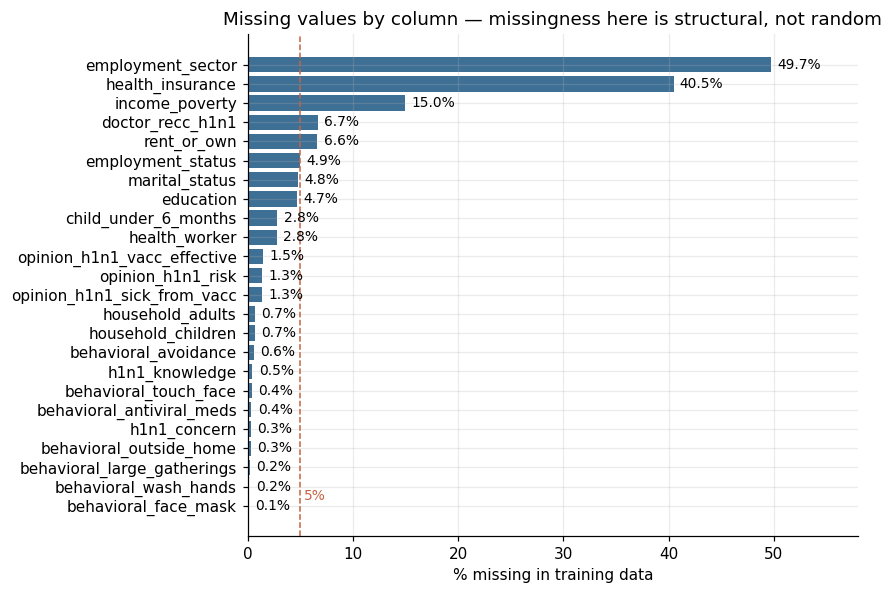

In [ ]:
miss = (train[FEATURES].isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
print(miss.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(miss.index[::-1], miss.values[::-1], color="#3E7096")
for i, v in enumerate(miss.values[::-1]):
    ax.text(v + 0.6, i, f"{v:.1f}%", va="center", fontsize=9)
ax.axvline(5, color="#C56443", ls="--", lw=1)
ax.text(5.4, 0.3, "5%", color="#C56443", fontsize=9)
ax.set_xlabel("% missing in training data")
ax.set_title("Missing values by column — missingness here is structural, not random")
ax.set_xlim(0, 58)
plt.show()

**Finding:** `employment_sector` (≈50%) and `health_insurance` (≈41%) are missing for a reason → keep **"missing" as its own category**.

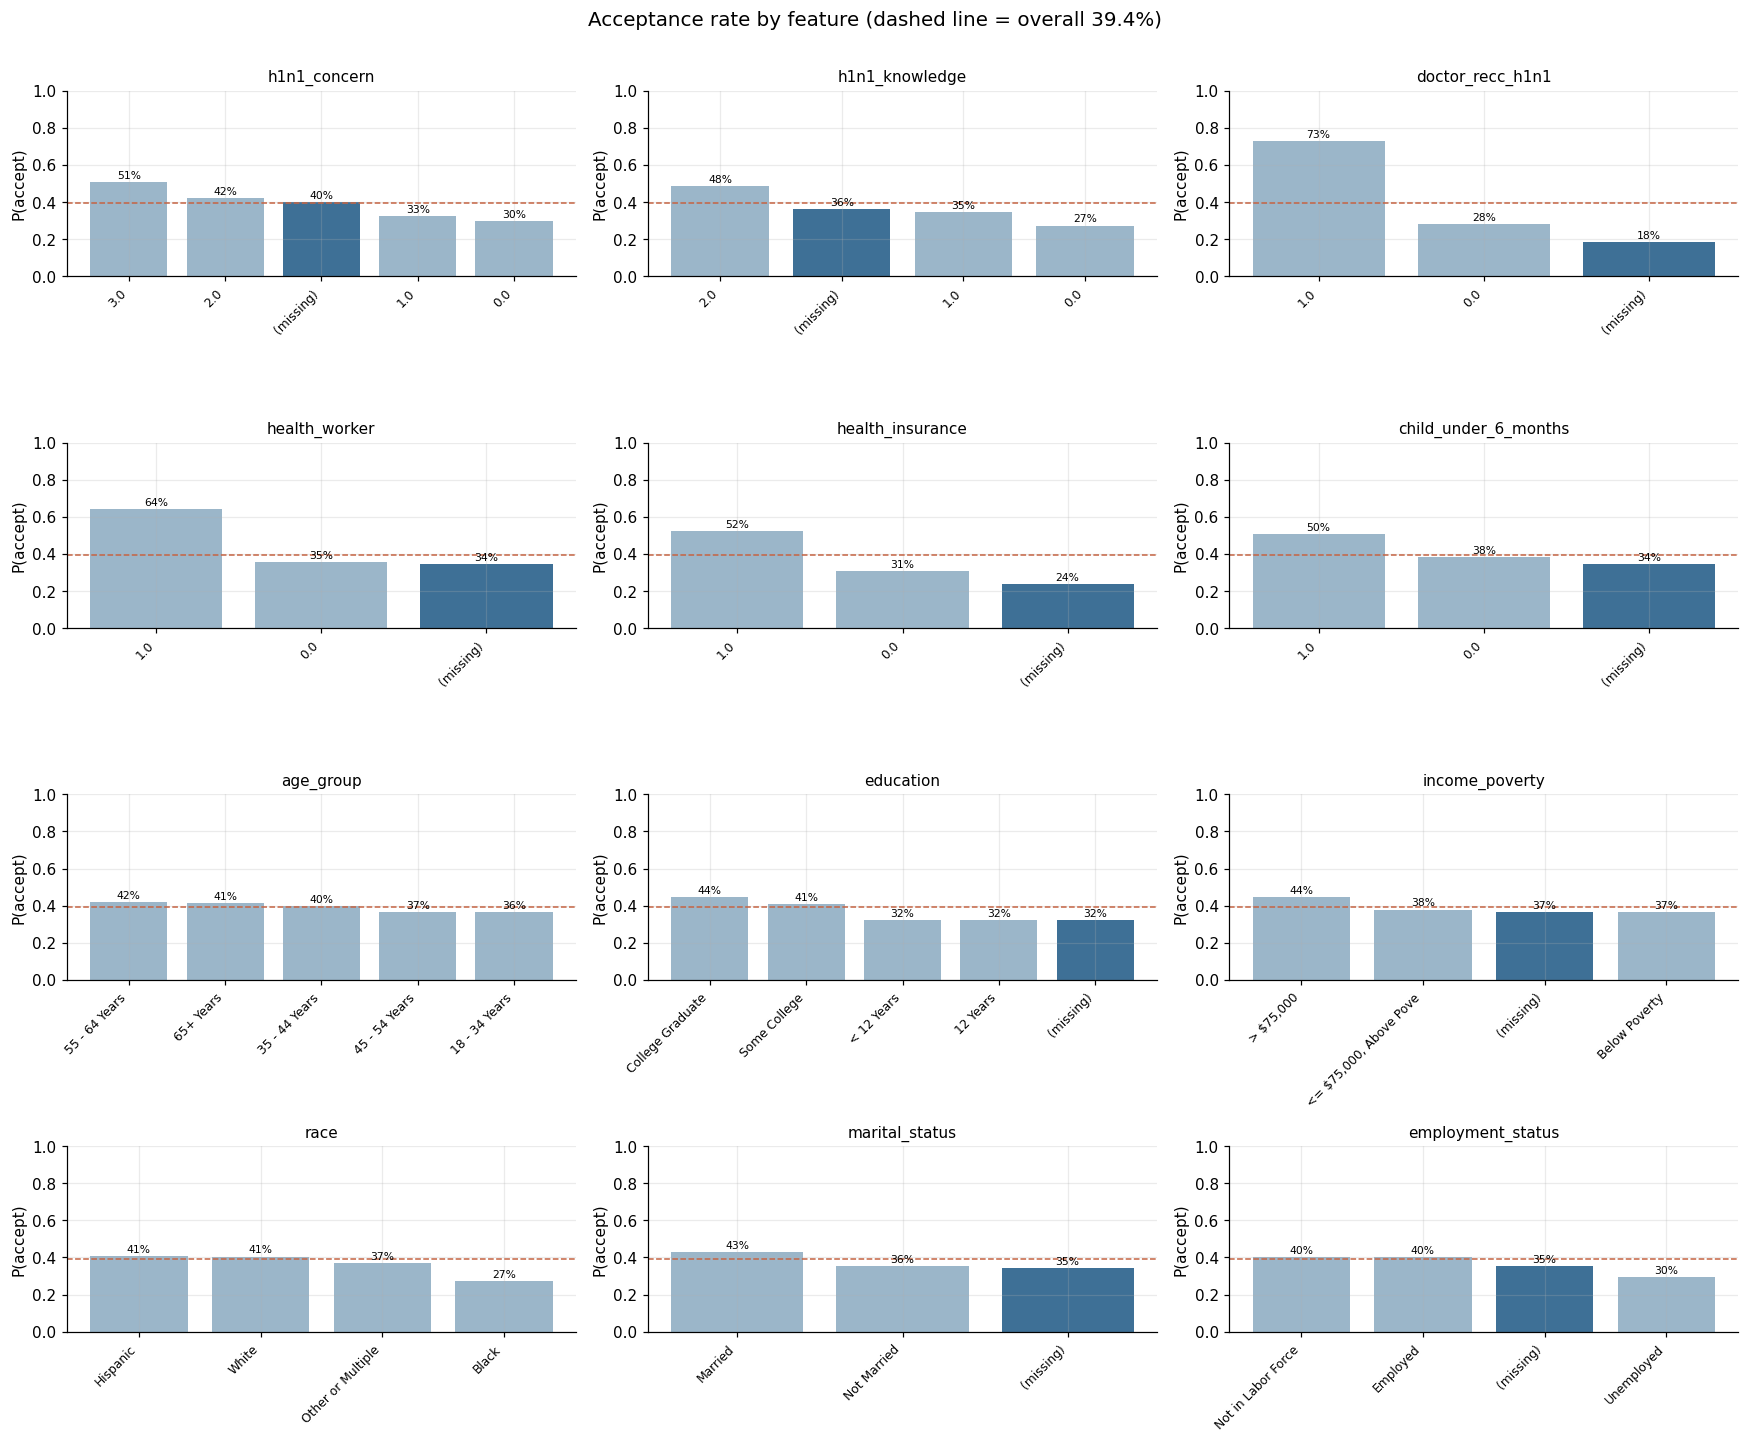

In [ ]:
def acceptance_by(col, ax, top=None):
    g = train.groupby(train[col].fillna("(missing)"))[TARGET].agg(["mean", "size"])
    g = g.sort_values("mean", ascending=False)
    if top:
        g = g.head(top)
    colors = ["#3E7096" if i == "(missing)" else "#9BB6C9" for i in g.index]
    ax.bar(range(len(g)), g["mean"], color=colors)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([str(i)[:22] for i in g.index], rotation=45, ha="right", fontsize=8)
    ax.axhline(y.mean(), color="#C56443", ls="--", lw=1)
    ax.set_title(col, fontsize=10)
    ax.set_ylim(0, 1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.02, f"{m:.0%}", ha="center", fontsize=7)
    ax.set_ylabel("P(accept)")


cat_cols = ["h1n1_concern", "h1n1_knowledge", "doctor_recc_h1n1", "health_worker",
            "health_insurance", "child_under_6_months", "age_group", "education",
            "income_poverty", "race", "marital_status", "employment_status"]
fig, axes = plt.subplots(4, 3, figsize=(16, 13))
for c, ax in zip(cat_cols, axes.ravel()):
    acceptance_by(c, ax)
fig.suptitle("Acceptance rate by feature (dashed line = overall 39.4%)", y=1.005, fontsize=13)
plt.tight_layout()
plt.show()

**Findings:**
* `doctor_recc_h1n1` is the strongest signal: 72.7% accept when recommended vs 27.9% when not (18.2% when missing).
* `health_insurance` missing → 23.6% accept vs 52.3% when insured.
* Acceptance rises with chronic conditions (36% → 46% → 51% → 58%).

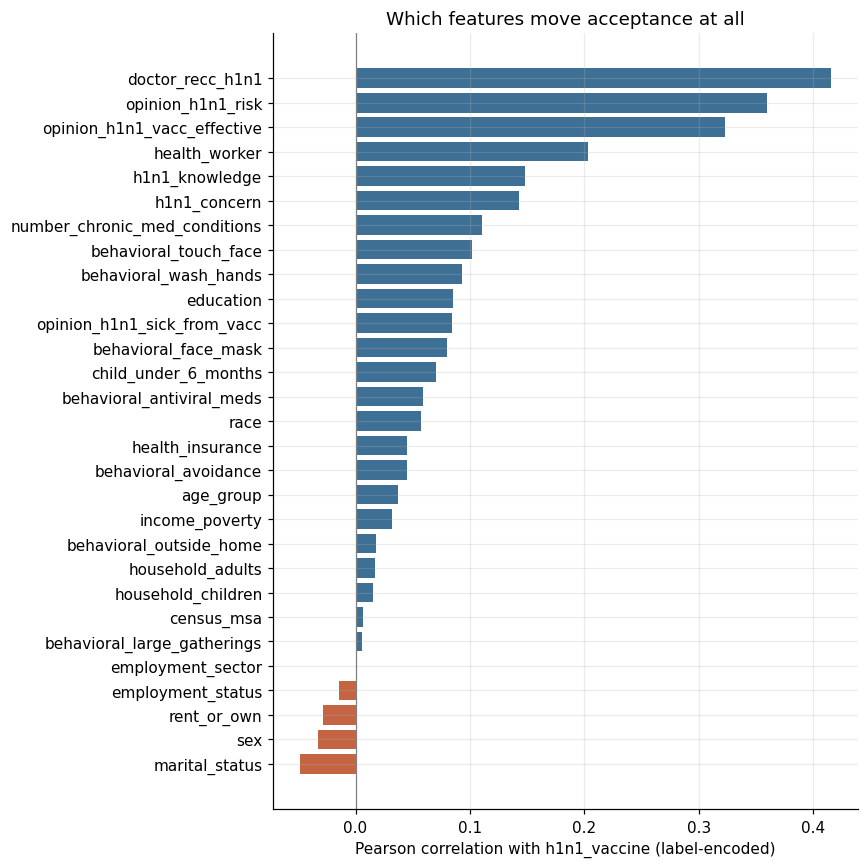


top 8 by |correlation|:
doctor_recc_h1n1                 0.416
opinion_h1n1_risk                0.359
opinion_h1n1_vacc_effective      0.323
health_worker                    0.203
h1n1_knowledge                   0.148
h1n1_concern                     0.143
number_chronic_med_conditions    0.111
behavioral_touch_face            0.102


In [ ]:
# Correlation of each feature with the target, on a label-encoded copy.
enc = X[FEATURES].copy()
for c in enc.columns:
    if not pd.api.types.is_numeric_dtype(enc[c]):
        # pandas >= 3 stores strings as dtype "str", not object, so test numerically
        enc[c] = enc[c].fillna("(missing)").astype("category").cat.codes
    else:
        enc[c] = enc[c].fillna(enc[c].median())
enc[TARGET] = y

corr_with_target = enc.corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
colors = ["#C56443" if v < 0 else "#3E7096" for v in corr_with_target.values]
ax.barh(corr_with_target.index, corr_with_target.values, color=colors)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("Pearson correlation with h1n1_vaccine (label-encoded)")
ax.set_title("Which features move acceptance at all")
plt.show()

print("\ntop 8 by |correlation|:")
print(corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index)
      .head(8).round(3).to_string())

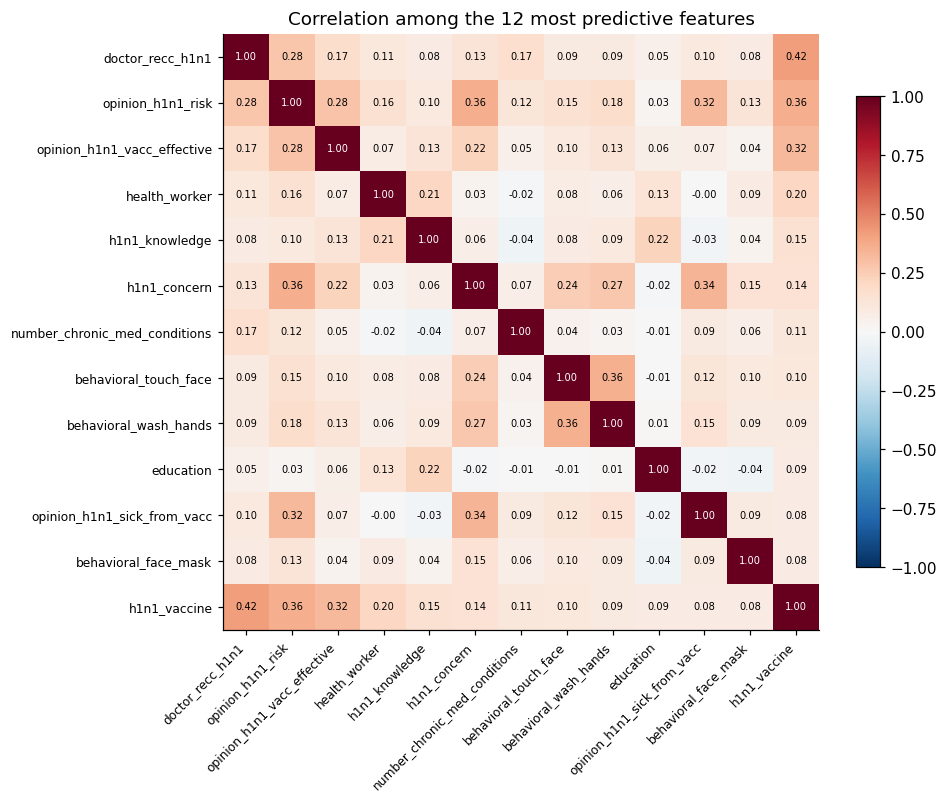

In [ ]:
top = corr_with_target.abs().sort_values(ascending=False).head(12).index.tolist()
sub = enc[top + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(sub.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(sub))); ax.set_xticklabels(sub.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(sub))); ax.set_yticklabels(sub.columns, fontsize=8)
for i in range(len(sub)):
    for j in range(len(sub)):
        ax.text(j, i, f"{sub.values[i, j]:.2f}", ha="center", va="center",
                fontsize=6.5, color="white" if abs(sub.values[i, j]) > 0.55 else "black")
ax.set_title("Correlation among the 12 most predictive features")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75)
plt.show()

**Finding:** opinion and concern variables carry most of the signal and are correlated → use regularised (L2) logistic regression. `behavioral_*` columns are weak.

## 3. Task-specific metric: the town's total cost

| Predict | Truth | Cost |
|---|---|---|
| send (1) | accepts (1) | 500 + p_vacc × 25,000 |
| send (1) | refuses (0) | 500 wasted + p_unvacc × 25,000 |
| don't send (0) | wanted it (1) | 500 paid instead + p_unvacc × 25,000 |
| don't send (0) | refuses (0) | p_unvacc × 25,000 |

**Decision rule:** send if P(accept) × (p_unvacc − p_vacc) × 25,000 > (1 − P(accept)) × 500,
i.e. **P(accept) > 0.02 / ((p_unvacc − p_vacc) + 0.02)**.

**Assumption (to confirm with tutor):** someone paid \$500 instead stays unvaccinated.

In [ ]:
def hospital_risk(chronic, ve=VACCINE_EFFECTIVENESS):
    """Return (p_unvacc, p_vacc) per person from the chronic-condition count."""
    c = np.asarray(chronic, dtype=float)
    c = np.where(np.isnan(c), 0.0, c)          # a blank condition count = no recorded conditions
    c = np.clip(c, 0, 3).astype(int)
    pu = np.vectorize(P_HOSP_UNVACC.get)(c).astype(float)
    return pu, pu * (1.0 - ve)


def decision_threshold(pu, ve=VACCINE_EFFECTIVENESS):
    """Per-person P(accept) that must be cleared before a dose is worth sending."""
    return 0.02 / (pu * ve + 0.02)


def total_cost(y_true, y_pred, chronic, ve=VACCINE_EFFECTIVENESS,
               cost_vaccine=COST_VACCINE, cost_hospital=COST_HOSPITAL):
    """Total $ the town spends. Lower is better.

    Implements the 2x2 cost table derived from the brief's rules:
      send + accepts        -> dose + hospital risk while vaccinated
      send + refuses        -> wasted dose + hospital risk while unvaccinated
      no send + wanted it   -> $500 compensation + hospital risk while unvaccinated
      no send + refuses     -> hospital risk while unvaccinated
    """
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    pu, pv = hospital_risk(chronic, ve)

    cost_sent  = cost_vaccine + np.where(y_true == 1, pv, pu) * cost_hospital
    cost_unsent = np.where(y_true == 1, cost_vaccine, 0) + pu * cost_hospital
    return float(np.where(y_pred == 1, cost_sent, cost_unsent).sum())


def decide(proba, chronic, ve=VACCINE_EFFECTIVENESS):
    """Turn per-person acceptance probabilities into 0/1 send decisions."""
    pu, _ = hospital_risk(chronic, ve)
    return (np.asarray(proba) > decision_threshold(pu, ve)).astype(int)


# ------------------------------------------------------------------ unit test
# Four people with 3+ chronic conditions: (predict, truth) covering all four cells.
pu, pv = hospital_risk([3, 3, 3, 3])
expected = (pu[0] * COST_HOSPITAL            # 0,0  -> 475
            + COST_VACCINE + pu[1] * COST_HOSPITAL   # 0,1  -> 975
            + COST_VACCINE + pv[0] * COST_HOSPITAL   # 1,1  -> 690
            + COST_VACCINE + pu[0] * COST_HOSPITAL)  # 1,0  -> 975
got = total_cost([0, 1, 1, 0], [0, 0, 1, 1], [3, 3, 3, 3])
assert np.isclose(got, expected), (got, expected)
print(f"unit test passed: 4-row cost table = ${got:,.0f}")

# Threshold table reproduced from first principles
rows = []
for c, pu_c in P_HOSP_UNVACC.items():
    thr = 0.02 / (pu_c * VACCINE_EFFECTIVENESS + 0.02)
    rows.append({"chronic": f"{c}{'+' if c == 3 else ''}",
                 "p_hosp_unvacc": pu_c,
                 "saving_per_dose": pu_c * VACCINE_EFFECTIVENESS,
                 "threshold": round(thr, 3)})
print(pd.DataFrame(rows).to_string(index=False))

unit test passed: 4-row cost table = $3,115
chronic  p_hosp_unvacc  saving_per_dose  threshold
      0         0.0024          0.00144      0.933
      1         0.0095          0.00570      0.778
      2         0.0140          0.00840      0.704
     3+         0.0190          0.01140      0.637


**Hospitalisation estimates (generative AI, as the brief allows; cross-checked with a second AI):**
* ~0.45% of 2009 H1N1 cases were hospitalised (CDC estimates)
* risk × 1 / 4 / 6 / 8 for 0 / 1 / 2 / 3+ chronic conditions (baseline 0.24%)
* vaccine prevents ~60% of hospitalisations (tested 40–80% in section 7)

→ thresholds **0.93 / 0.78 / 0.70 / 0.64** for 0 / 1 / 2 / 3+ conditions.

## 4. Pre-processing

| | Variant A | Variant B |
|---|---|---|
| Ordinal / numeric | median imputation | `-1` = not answered |
| Nominal | most frequent, then one-hot | `"(missing)"` category, then one-hot |

Ordered columns (`age_group`, `education`, `income_poverty`) are encoded in order. Scaling only for logistic regression.

In [ ]:
ORDINAL_CATEGORIES = {
    "h1n1_concern":                  [0.0, 1.0, 2.0, 3.0],
    "h1n1_knowledge":                [0.0, 1.0, 2.0],
    "opinion_h1n1_vacc_effective":   [1.0, 2.0, 3.0, 4.0, 5.0],
    "opinion_h1n1_risk":             [1.0, 2.0, 3.0, 4.0, 5.0],
    "opinion_h1n1_sick_from_vacc":   [1.0, 2.0, 3.0, 4.0, 5.0],
    "age_group":                     ["18 - 34 Years", "35 - 44 Years", "45 - 54 Years",
                                      "55 - 64 Years", "65+ Years"],
    "education":                     ["< 12 Years", "12 Years", "Some College", "College Graduate"],
    "income_poverty":                ["Below Poverty", "<= $75,000, Above Poverty", "> $75,000"],
}

BINARY_COLS = ["behavioral_antiviral_meds", "behavioral_avoidance", "behavioral_face_mask",
               "behavioral_wash_hands", "behavioral_large_gatherings", "behavioral_outside_home",
               "behavioral_touch_face", "doctor_recc_h1n1", "child_under_6_months",
               "health_worker", "health_insurance", "household_adults", "household_children",
               "number_chronic_med_conditions"]

NOMINAL_COLS = ["race", "sex", "marital_status", "rent_or_own",
                "employment_status", "census_msa", "employment_sector"]

ORDINAL_COLS = list(ORDINAL_CATEGORIES)

assert sorted(ORDINAL_COLS + BINARY_COLS + NOMINAL_COLS) == sorted(FEATURES)
print(f"{len(ORDINAL_COLS)} ordinal, {len(BINARY_COLS)} binary/numeric, {len(NOMINAL_COLS)} nominal")


def make_preprocessor(variant: str = "B") -> ColumnTransformer:
    """Build the encoding pipeline. variant='A' imputes; variant='B' keeps missing as a category."""
    if variant not in {"A", "B"}:
        raise ValueError(variant)

    if variant == "A":
        ord_imp = SimpleImputer(strategy="median")
        bin_imp = SimpleImputer(strategy="median")
        nom_imp = SimpleImputer(strategy="most_frequent")
    else:
        ord_imp = SimpleImputer(strategy="constant", fill_value=-1)
        bin_imp = SimpleImputer(strategy="constant", fill_value=-1)
        nom_imp = SimpleImputer(strategy="constant", fill_value="(missing)")

    ord_pipe = Pipeline([
        ("encode", OrdinalEncoder(categories=[ORDINAL_CATEGORIES[c] for c in ORDINAL_COLS],
                                  handle_unknown="use_encoded_value", unknown_value=-1)),
        ("impute", ord_imp),
    ])
    bin_pipe = Pipeline([("impute", bin_imp)])
    nom_pipe = Pipeline([
        ("impute", nom_imp),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer([
        ("ord", ord_pipe, ORDINAL_COLS),
        ("bin", bin_pipe, BINARY_COLS),
        ("nom", nom_pipe, NOMINAL_COLS),
    ])


def make_pipeline(model, variant="B", scale=False):
    """Pre-processor + optional scaler + estimator, in that order."""
    steps = [("prep", make_preprocessor(variant))]
    if scale:
        steps.append(("scale", StandardScaler(with_mean=False)))
    steps.append(("model", model))
    return Pipeline(steps)


# Stratified split. `chronic` is carried through because the metric needs it per person.
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

chronic_tr  = X_tr["number_chronic_med_conditions"].values
chronic_val = X_val["number_chronic_med_conditions"].values

print(f"train {X_tr.shape}  accept {y_tr.mean():.1%}")
print(f"valid {X_val.shape}  accept {y_val.mean():.1%}")

8 ordinal, 14 binary/numeric, 7 nominal
train (3804, 29)  accept 39.4%
valid (952, 29)  accept 39.4%


### 4.1 Comparing the two variants (logistic regression, same folds)

In [ ]:
from sklearn.model_selection import cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
variant_rows = []
for v in ["A", "B"]:
    pipe = make_pipeline(LogisticRegression(max_iter=2000, C=0.5), variant=v, scale=True)
    auc = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc")
    variant_rows.append({"variant": v, "mean_auc": auc.mean(), "sd": auc.std()})

comparison = pd.DataFrame(variant_rows)
print(comparison.round(4).to_string(index=False))
best_variant = comparison.loc[comparison.mean_auc.idxmax(), "variant"]
print(f"\n-> using variant {best_variant} for the models below")

variant  mean_auc     sd
      A    0.8163 0.0106
      B    0.8388 0.0065

-> using variant B for the models below


**Result:** variant B wins → used for all models.

## 5. Modelling, tuning & cross-validation

Logistic regression, random forest, gradient boosting, hist gradient boosting, extra trees. Tuned with `GridSearchCV` (ROC AUC), then calibrated (isotonic) because the decision rule needs accurate probabilities.

In [ ]:
base_models = {
    "LogReg":  (make_pipeline(LogisticRegression(max_iter=3000, C=1.0), best_variant, scale=True), {}),
    "RandomForest": (make_pipeline(RandomForestClassifier(
        n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1), best_variant),
        {"model__max_depth": [6, 10, None], "model__min_samples_leaf": [1, 5]}),
    "GradBoost": (make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE), best_variant),
        {"model__n_estimators": [150, 300], "model__learning_rate": [0.05, 0.1],
         "model__max_depth": [2, 3]}),
    "HistGB":  (make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE), best_variant),
        {"model__learning_rate": [0.05, 0.1], "model__max_depth": [3, 5]}),
    "ExtraTrees": (make_pipeline(ExtraTreesClassifier(
        n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1), best_variant),
        {"model__max_depth": [10, None], "model__min_samples_leaf": [1, 5]}),
}

tuned = {}
tuning_rows = []
for name, (pipe, grid) in base_models.items():
    if grid:
        search = GridSearchCV(pipe, grid, cv=3, scoring="roc_auc", n_jobs=-1, refit=True)
        search.fit(X_tr, y_tr)
        tuned[name] = search.best_estimator_
        tuning_rows.append({"model": name, "best_cv_auc": search.best_score_,
                            "params": {k.replace("model__", ""): v
                                       for k, v in search.best_params_.items()}})
    else:
        pipe.fit(X_tr, y_tr)
        tuned[name] = pipe
        # No grid to search, but the score must still be cross-validated: an in-sample AUC
        # sitting next to three genuine CV scores would flatter this row.
        cv_auc = cross_val_score(pipe, X_tr, y_tr, cv=3, scoring="roc_auc").mean()
        tuning_rows.append({"model": name, "best_cv_auc": cv_auc, "params": {"C": 1.0}})

for r in tuning_rows:
    print(f"{r['model']:13s} cv_auc={r['best_cv_auc']:.4f}  {r['params']}")

LogReg        cv_auc=0.8374  {'C': 1.0}
RandomForest  cv_auc=0.8552  {'max_depth': 10, 'min_samples_leaf': 1}
GradBoost     cv_auc=0.8548  {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300}
HistGB        cv_auc=0.8534  {'learning_rate': 0.1, 'max_depth': 3}
ExtraTrees    cv_auc=0.8507  {'max_depth': 10, 'min_samples_leaf': 5}


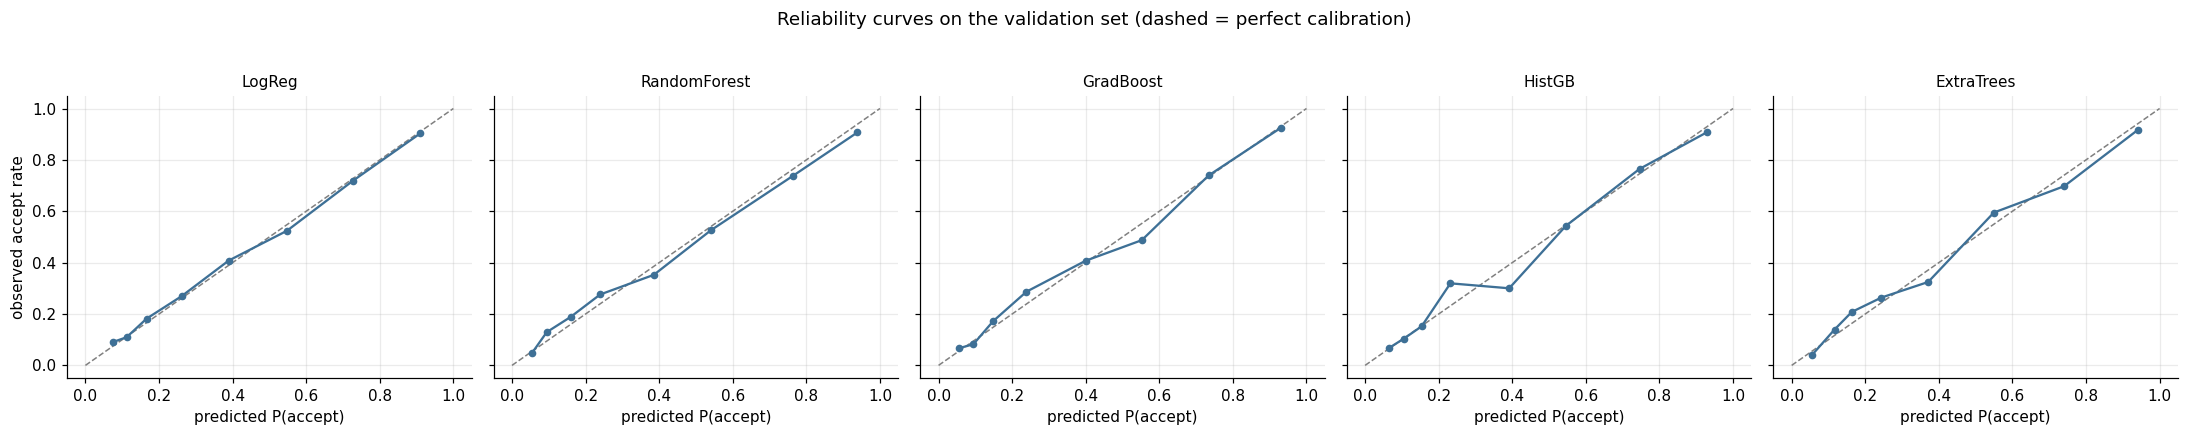

       model    auc  brier
      HistGB 0.8446 0.1530
   GradBoost 0.8429 0.1541
  ExtraTrees 0.8400 0.1563
RandomForest 0.8364 0.1574
      LogReg 0.8295 0.1600


In [ ]:
# Calibrate: isotonic on the training fold, then check the reliability curve on validation.
calibrated = {}
for name, pipe in tuned.items():
    cal = CalibratedClassifierCV(pipe, method="isotonic", cv=3, n_jobs=-1)
    cal.fit(X_tr, y_tr)
    calibrated[name] = cal

fig, axes = plt.subplots(1, len(calibrated), figsize=(4 * len(calibrated), 3.8), sharey=True)
rows = []
for ax, (name, model) in zip(np.atleast_1d(axes), calibrated.items()):
    p = model.predict_proba(X_val)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_val, p, n_bins=8, strategy="quantile")
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
    ax.plot(mean_pred, frac_pos, "o-", color="#3E7096", lw=1.5, ms=4)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("predicted P(accept)")
    rows.append({"model": name, "auc": roc_auc_score(y_val, p),
                 "brier": brier_score_loss(y_val, p)})
np.atleast_1d(axes)[0].set_ylabel("observed accept rate")
fig.suptitle("Reliability curves on the validation set (dashed = perfect calibration)", y=1.03)
plt.show()

metrics = pd.DataFrame(rows).sort_values("brier")
print(metrics.round(4).to_string(index=False))

## 6. Cost-based decisions & model comparison

Total cost on the validation set vs the baselines: send nobody, send everyone, perfect predictions.

In [ ]:
def cost_row(name, y_true, y_pred, chronic):
    return {"strategy": name,
            "total_cost": total_cost(y_true, y_pred, chronic),
            "doses_sent": int(np.sum(y_pred))}


val_baselines = [
    cost_row("send nobody", y_val, np.zeros_like(y_val), chronic_val),
    cost_row("send everyone", y_val, np.ones_like(y_val), chronic_val),
    cost_row("perfect (oracle)", y_val, y_val.copy(), chronic_val),
]

for name, model in calibrated.items():
    p = model.predict_proba(X_val)[:, 1]
    val_baselines.append(cost_row(name, y_val, decide(p, chronic_val), chronic_val))

results = pd.DataFrame(val_baselines).sort_values("total_cost")
results["vs_send_nobody"] = results.total_cost - results.loc[
    results.strategy == "send nobody", "total_cost"].values[0]
print(results.round(0).to_string(index=False))

        strategy  total_cost  doses_sent  vs_send_nobody
perfect (oracle)    273372.0         375        -31346.0
       GradBoost    297506.0         100         -7212.0
      ExtraTrees    297572.0         109         -7146.0
          HistGB    297684.0         104         -7033.0
    RandomForest    297789.0         122         -6928.0
          LogReg    298678.0          86         -6039.0
     send nobody    304718.0           0             0.0
   send everyone    561872.0         952        257154.0


**Findings:**
* Send everyone ≈ double the cost of sending nobody.
* All models beat send nobody, but by a small margin.
* Perfect predictions are only ~10% cheaper than sending nobody.

best model on validation cost: GradBoost


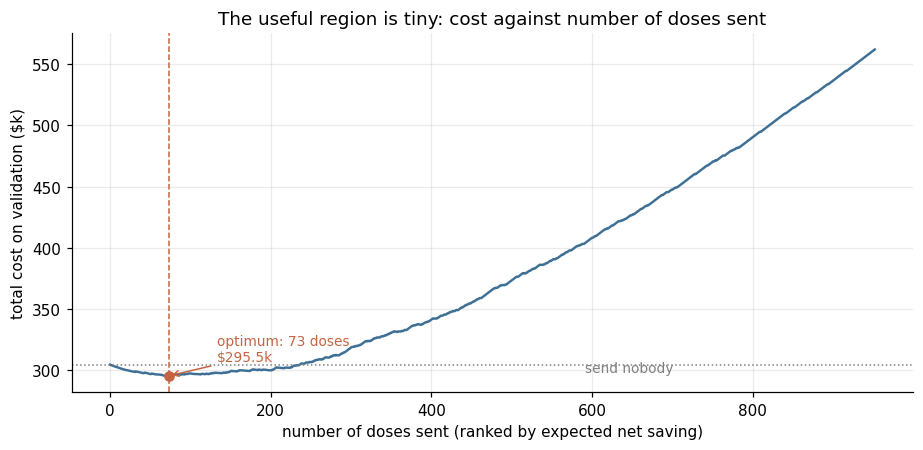

k*=73  cost=$295,542  vs send-nobody $304,718 (gain $9,176)
people with positive expected net saving: 100 of 952


In [ ]:
# Cost as a function of how many doses we send, ranked by expected net saving.
best_name = results[results.strategy.isin(calibrated)].iloc[0]["strategy"]
best_model = calibrated[best_name]
print("best model on validation cost:", best_name)

p_val = best_model.predict_proba(X_val)[:, 1]
pu_val, _ = hospital_risk(chronic_val)

# Expected dollars saved by sending this person one dose (negative = expected loss)
net = p_val * (pu_val * VACCINE_EFFECTIVENESS) * COST_HOSPITAL - (1 - p_val) * COST_VACCINE
order = np.argsort(-net)

costs = []
for k in range(0, len(net) + 1):
    pred = np.zeros(len(net), dtype=int)
    pred[order[:k]] = 1
    costs.append(total_cost(y_val, pred, chronic_val))
costs = np.array(costs)
k_star = int(np.argmin(costs))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(range(len(costs)), costs / 1000, color="#3E7096", lw=1.6)
ax.axvline(k_star, color="#C56443", ls="--", lw=1)
ax.scatter([k_star], [costs[k_star] / 1000], color="#C56443", zorder=5)
ax.annotate(f"optimum: {k_star} doses\n${costs[k_star]/1000:,.1f}k",
            xy=(k_star, costs[k_star] / 1000), xytext=(k_star + 60, costs[k_star] / 1000 + 12),
            fontsize=9, color="#C56443",
            arrowprops=dict(arrowstyle="->", color="#C56443", lw=1))
ax.axhline(costs[0] / 1000, color="gray", ls=":", lw=1)
ax.text(len(costs) * 0.62, costs[0] / 1000 - 6, "send nobody", color="gray", fontsize=9)
ax.set_xlabel("number of doses sent (ranked by expected net saving)")
ax.set_ylabel("total cost on validation ($k)")
ax.set_title("The useful region is tiny: cost against number of doses sent")
plt.show()

print(f"k*={k_star}  cost=${costs[k_star]:,.0f}  vs send-nobody ${costs[0]:,.0f} "
      f"(gain ${costs[0]-costs[k_star]:,.0f})")
print(f"people with positive expected net saving: {(net > 0).sum()} of {len(net)}")

**Finding:** cost is lowest at k* = 73 doses and rises after that → only a small group is worth vaccinating.

In [ ]:
# 5-fold cost variability: a point estimate is not enough.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, model in calibrated.items():
    fold_costs = []
    for tr_idx, va_idx in skf.split(X, y):
        Xa, Xb = X.iloc[tr_idx], X.iloc[va_idx]
        ya, yb = y[tr_idx], y[va_idx]
        # clone() gives an unfitted copy of the *tuned* pipeline, so the CV loop
        # re-uses the same hyper-parameters that were selected on the 80/20 split.
        m = CalibratedClassifierCV(clone(tuned[name]), method="isotonic", cv=2, n_jobs=-1)
        m.fit(Xa, ya)
        fold_costs.append(total_cost(yb, decide(m.predict_proba(Xb)[:, 1],
                                                X.iloc[va_idx]["number_chronic_med_conditions"].values),
                                     X.iloc[va_idx]["number_chronic_med_conditions"].values))
    cv_rows.append({"model": name, "mean_cost": np.mean(fold_costs),
                    "sd_cost": np.std(fold_costs), "min": np.min(fold_costs),
                    "max": np.max(fold_costs)})

cv_table = pd.DataFrame(cv_rows).sort_values("mean_cost")
print(cv_table.round(0).to_string(index=False))

       model  mean_cost  sd_cost      min      max
RandomForest   296563.0   4011.0 290069.0 300444.0
      HistGB   296690.0   3792.0 291067.0 300756.0
   GradBoost   297043.0   3925.0 290822.0 301548.0
  ExtraTrees   297236.0   3925.0 290319.0 301908.0
      LogReg   298084.0   3915.0 291389.0 302043.0


**Finding:** fold-to-fold spread (~\$4,000) is larger than the gaps between models → no single clear winner.

## 7. Sensitivity analysis on the cost assumptions

In [ ]:
# Sensitivity: does the decision (and the model ranking) survive different assumptions?
sens_rows = []
for ve in [0.40, 0.60, 0.80]:
    for mult in [1.0, 2.0]:
        risk = {k: v * mult for k, v in P_HOSP_UNVACC.items()}
        saved = dict(P_HOSP_UNVACC)
        P_HOSP_UNVACC.update(risk)
        for name, model in calibrated.items():
            p = model.predict_proba(X_val)[:, 1]
            sens_rows.append({"ve": ve, "risk_mult": mult, "model": name,
                              "cost": total_cost(y_val, decide(p, chronic_val, ve), chronic_val, ve),
                              "doses": int(decide(p, chronic_val, ve).sum())})
        P_HOSP_UNVACC.clear(); P_HOSP_UNVACC.update(saved)

sens = pd.DataFrame(sens_rows)
pivot = sens.pivot_table(index=["ve", "risk_mult"], columns="model", values="cost")
print((pivot / 1000).round(1).to_string())

model          ExtraTrees  GradBoost  HistGB  LogReg  RandomForest
ve  risk_mult                                                     
0.4 1.0             301.9      300.4   300.0   302.4         301.0
    2.0             412.1      410.0   410.3   410.5         409.3
0.6 1.0             297.6      297.5   297.7   298.7         297.8
    2.0             399.5      399.3   399.0   401.3         399.7
0.8 1.0             294.9      292.8   293.1   293.2         292.1
    2.0             388.9      386.7   388.7   387.9         387.7


**Findings:**
* Higher vaccine effectiveness → lower cost.
* Doubled hospitalisation risk → higher cost.
* The best model changes between scenarios → we submit different decision rules, not one model.

## 8. Final predictions — top 5 submission files

| Rule | What it does |
|---|---|
| `threshold_person` | per-person threshold by chronic conditions |
| `threshold_strict` | same, assuming 40% vaccine effectiveness |
| `threshold_global` | one cut-off for everyone, tuned by CV |
| `top_k` | top *k*% by expected saving, *k* tuned by CV |
| `cell_rule` | no model: acceptance rate by chronic × doctor recommendation |
| `send_nobody` | baseline / safe fallback |

In [ ]:
def fit_best(Xa, ya):
    """Refit the tuned best model on whatever training data it is given, with calibration."""
    m = CalibratedClassifierCV(clone(tuned[best_name]), method="isotonic", cv=3, n_jobs=-1)
    m.fit(Xa, ya)
    return m


def _chronic(df):
    return df["number_chronic_med_conditions"].values


def _net_saving(p, chronic, ve=VACCINE_EFFECTIVENESS):
    """Expected $ saved by sending one dose to this person (negative = expected loss)."""
    pu, _ = hospital_risk(chronic, ve)
    return p * (pu * ve) * COST_HOSPITAL - (1 - p) * COST_VACCINE


def _cv_proba(Xa, ya, cv=3):
    """Out-of-fold probabilities on the training fold, used to tune k and the global cut-off.

    Uses the SAME calibrated model as fit_best(), so the cut-off / k learned here is applied
    to probabilities on the same scale at prediction time.
    """
    from sklearn.model_selection import cross_val_predict
    cal = CalibratedClassifierCV(clone(tuned[best_name]), method="isotonic", cv=3)
    return cross_val_predict(cal, Xa, ya, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]


def threshold_person(Xa, ya, Xb):
    m = fit_best(Xa, ya)
    return decide(m.predict_proba(Xb)[:, 1], _chronic(Xb))


def threshold_global(Xa, ya, Xb):
    p_a = _cv_proba(Xa, ya)
    cand = np.unique(np.round(p_a, 2))
    costs = [total_cost(ya, (p_a > t).astype(int), _chronic(Xa)) for t in cand]
    t_star = cand[int(np.argmin(costs))]
    m = fit_best(Xa, ya)
    return (m.predict_proba(Xb)[:, 1] > t_star).astype(int)


def top_k(Xa, ya, Xb):
    p_a = _cv_proba(Xa, ya)
    order_a = np.argsort(-_net_saving(p_a, _chronic(Xa)))
    costs = []
    for k in range(0, len(p_a) + 1):
        pred = np.zeros(len(p_a), dtype=int)
        pred[order_a[:k]] = 1
        costs.append(total_cost(ya, pred, _chronic(Xa)))
    k_star = int(np.argmin(costs))
    k_frac = k_star / len(p_a)                     # a share of the population, not a raw count,
    k_b = int(round(k_frac * len(Xb)))             # so it transfers to a set of a different size

    m = fit_best(Xa, ya)
    p_b = m.predict_proba(Xb)[:, 1]
    pred = np.zeros(len(Xb), dtype=int)
    pred[np.argsort(-_net_saving(p_b, _chronic(Xb)))[:k_b]] = 1
    return pred


def cell_rule(Xa, ya, Xb):
    """No model: send where the empirical acceptance rate in a cell clears the required threshold."""
    def key(df):
        c = np.clip(np.nan_to_num(df["number_chronic_med_conditions"].values, nan=0.0), 0, 3)
        d = df["doctor_recc_h1n1"].fillna(-1).values
        return pd.Series(list(zip(c.astype(int), d)), index=df.index)

    rates = pd.Series(ya.astype(float), index=Xa.index).groupby(key(Xa)).mean()
    k_b = key(Xb)
    p_b = k_b.map(rates).fillna(0.0).values
    return decide(p_b, _chronic(Xb))


def threshold_strict(Xa, ya, Xb):
    m = fit_best(Xa, ya)
    return decide(m.predict_proba(Xb)[:, 1], _chronic(Xb), ve=0.40)


CANDIDATES = {
    "threshold_person": threshold_person,
    "threshold_global": threshold_global,
    "threshold_strict": threshold_strict,
    "top_k":            top_k,
    "cell_rule":        cell_rule,
    "send_nobody":      lambda Xa, ya, Xb: np.zeros(len(Xb), dtype=int),
}

print("candidates:", ", ".join(CANDIDATES))

candidates: threshold_person, threshold_global, threshold_strict, top_k, cell_rule, send_nobody


In [ ]:
# Score every candidate on the validation split with the *same* code path used for test predictions.
rank_rows, val_preds = [], {}
for name, fn in CANDIDATES.items():
    pred_val = fn(X_tr, y_tr, X_val)
    val_preds[name] = pred_val
    rank_rows.append({"strategy": name,
                      "val_cost": total_cost(y_val, pred_val, chronic_val),
                      "doses_val": int(pred_val.sum())})

ranking = pd.DataFrame(rank_rows).sort_values("val_cost").reset_index(drop=True)
ranking["rank"] = ranking.index + 1
ranking["gain_vs_nobody"] = (ranking.val_cost
                             - ranking.loc[ranking.strategy == "send_nobody", "val_cost"].values[0])
print(ranking.round(0).to_string(index=False))

        strategy  val_cost  doses_val  rank  gain_vs_nobody
threshold_strict  297064.0         83     1         -7654.0
threshold_person  297506.0        100     2         -7212.0
           top_k  297902.0        136     3         -6815.0
threshold_global  299332.0         96     4         -5386.0
       cell_rule  300942.0         29     5         -3775.0
     send_nobody  304718.0          0     6             0.0


**Result:** ranked by validation cost. We submit the 4 best rules + "send nobody" as a fallback.

In [ ]:
# Keep the four best distinct rules (skip any that make identical decisions), plus "send nobody".
seen, distinct = {}, []
for _, row in ranking.iterrows():
    name = row["strategy"]
    if name == "send_nobody":
        continue
    key = val_preds[name].tobytes()
    if key in seen:
        print(f"{name:18s} identical to {seen[key]} on validation -> collapsed")
        continue
    seen[key] = name
    distinct.append(name)

submission_set = distinct[:4]
if "send_nobody" not in submission_set:
    submission_set.append("send_nobody")
print("submission slots:", submission_set)

val_cost = dict(zip(ranking.strategy, ranking.val_cost))

# Refit on the full training set and write the five submission files.
summary = []
for slot, name in enumerate(submission_set, start=1):
    pred_test = CANDIDATES[name](X, y, X_test)
    order = slot

    sub = pd.DataFrame({ID: test_ids, TARGET: pred_test.astype(int)})
    path = SUBMIT_DIR / f"challenge_submission_group_{GROUP}_order_{order}.csv"
    sub.to_csv(path, index=False)

    summary.append({"file": path.name, "strategy": name,
                    "val_cost": val_cost[name], "doses_test": int(pred_test.sum()),
                    "share_of_town": pred_test.mean()})

summary = pd.DataFrame(summary)
print(summary.round(3).to_string(index=False))

submission slots: ['threshold_strict', 'threshold_person', 'top_k', 'threshold_global', 'send_nobody']
                                    file         strategy  val_cost  doses_test  share_of_town
challenge_submission_group_0_order_1.csv threshold_strict  297064.0         425          0.089
challenge_submission_group_0_order_2.csv threshold_person  297505.5         560          0.118
challenge_submission_group_0_order_3.csv            top_k  297902.5         502          0.106
challenge_submission_group_0_order_4.csv threshold_global  299331.5         684          0.144
challenge_submission_group_0_order_5.csv      send_nobody  304717.5           0          0.000


In [ ]:
# Hard checks before anything is uploaded — a malformed file scores nothing.
ref_ids = example[ID].tolist()
ok = True
for _, row in summary.iterrows():
    f = SUBMIT_DIR / row["file"]
    df = pd.read_csv(f)
    checks = {
        "2 columns":       list(df.columns) == [ID, TARGET],
        "4,749 rows":      len(df) == len(example),
        "same ids in order": df[ID].tolist() == ref_ids,
        "values are 0/1":  set(df[TARGET].unique()) <= {0, 1},
        "no nulls":        df.notna().all().all(),
    }
    failed = [k for k, v in checks.items() if not v]
    ok &= not failed
    print(f"{row['file']:46s} {'PASS' if not failed else 'FAIL: ' + ', '.join(failed)}")

print("\nALL CHECKS PASSED" if ok else "\nSOMETHING IS WRONG - DO NOT SUBMIT")

challenge_submission_group_0_order_1.csv       PASS
challenge_submission_group_0_order_2.csv       PASS
challenge_submission_group_0_order_3.csv       PASS
challenge_submission_group_0_order_4.csv       PASS
challenge_submission_group_0_order_5.csv       PASS

ALL CHECKS PASSED


In [ ]:
# Download the 5 submission files automatically (works in Colab; elsewhere they stay in submissions/).
import shutil
if GROUP == 0:
    print("WARNING: GROUP is still 0 - set your group number in section 0 and re-run before submitting!")
print("files written:", sorted(f.name for f in SUBMIT_DIR.glob("*.csv")))
try:
    from google.colab import files
    for f in sorted(SUBMIT_DIR.glob("*.csv")):
        files.download(str(f))           # one download per CSV, ready to upload to Canvas
except ImportError:
    print(f"Not running in Colab - the files are in the folder: {SUBMIT_DIR.resolve()}")

files written: ['challenge_submission_group_0_order_1.csv', 'challenge_submission_group_0_order_2.csv', 'challenge_submission_group_0_order_3.csv', 'challenge_submission_group_0_order_4.csv', 'challenge_submission_group_0_order_5.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Who receives the doses in each submission (used in the conclusions).
comp = []
for _, row in summary.iterrows():
    p = pd.read_csv(SUBMIT_DIR / row["file"])
    m = test.merge(p, on=ID)
    d = m[m[TARGET] == 1]
    comp.append({
        "slot": row["file"].split("order_")[-1].replace(".csv", ""),
        "doses": len(d),
        "doctor_recommended": (d["doctor_recc_h1n1"] == 1).mean() if len(d) else float("nan"),
        "at_least_1_condition": (d["number_chronic_med_conditions"] >= 1).mean() if len(d) else float("nan"),
    })
comp = pd.DataFrame(comp)
print(comp.round(3).to_string(index=False))

slot  doses  doctor_recommended  at_least_1_condition
   1    425               0.866                 0.706
   2    560               0.839                 0.632
   3    502               0.849                 0.685
   4    684               0.819                 0.420
   5      0                 NaN                   NaN


## 9. Explainable AI

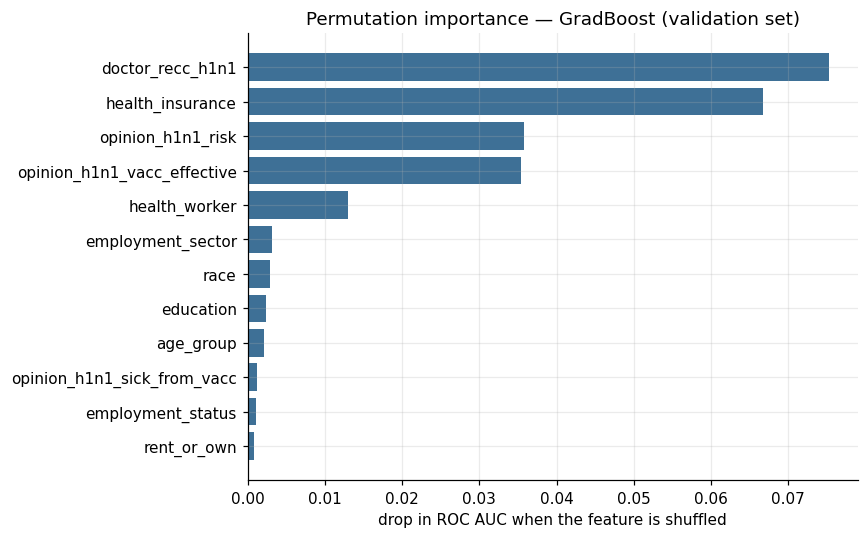

doctor_recc_h1n1               0.0753
health_insurance               0.0667
opinion_h1n1_risk              0.0357
opinion_h1n1_vacc_effective    0.0354
health_worker                  0.0130
employment_sector              0.0032
race                           0.0029
education                      0.0024
age_group                      0.0021
opinion_h1n1_sick_from_vacc    0.0013
employment_status              0.0010
rent_or_own                    0.0009


In [ ]:
prep = tuned[best_name].named_steps["prep"]
est  = tuned[best_name].named_steps["model"]

perm = permutation_importance(tuned[best_name], X_val, y_val, n_repeats=10,
                              random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index[::-1], imp.values[::-1], color="#3E7096")
ax.set_xlabel("drop in ROC AUC when the feature is shuffled")
ax.set_title(f"Permutation importance — {best_name} (validation set)")
plt.show()
print(imp.round(4).to_string())

Permutation importance = drop in AUC when a feature is shuffled (validation set).

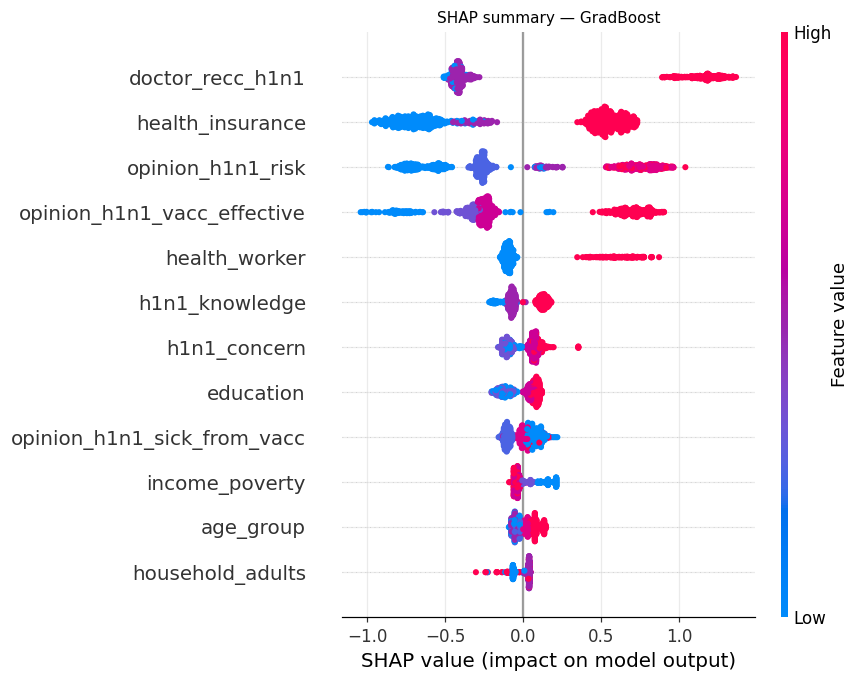

SHAP computed: (952, 62)


In [ ]:
# SHAP — installed by default in Colab. Guarded so the notebook still runs without it.
try:
    import shap

    X_val_t = prep.transform(X_val)
    if hasattr(X_val_t, "toarray"):
        X_val_t = X_val_t.toarray()
    feat_names = prep.get_feature_names_out()
    feat_names = [f.split("__", 1)[-1] for f in feat_names]

    explainer = shap.TreeExplainer(est)
    sv = explainer.shap_values(X_val_t)
    if isinstance(sv, list):
        sv = sv[1]

    shap.summary_plot(sv, X_val_t, feature_names=feat_names, max_display=12, show=False)
    plt.title(f"SHAP summary — {best_name}", fontsize=10)
    plt.tight_layout()
    plt.show()
    print("SHAP computed:", sv.shape)
except ImportError:
    print("shap not installed -> run `!pip install shap` (Colab has it by default). "
          "The permutation-importance plot above stands in for it.")

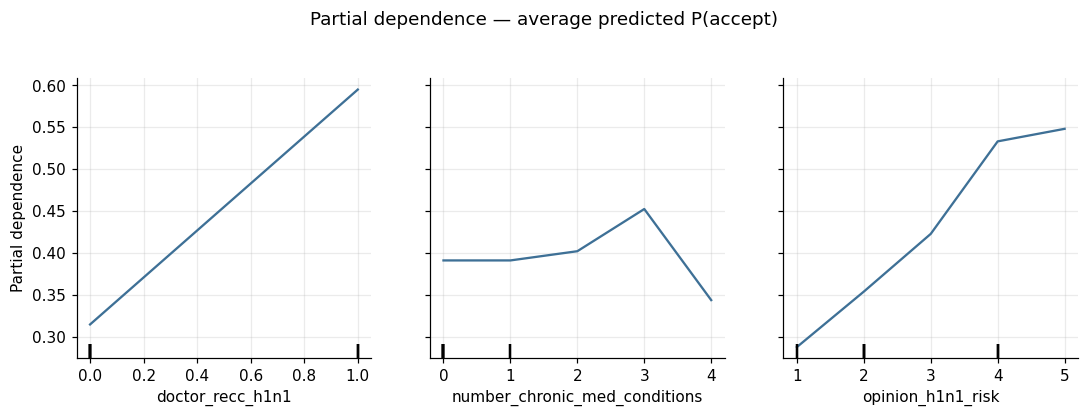

In [ ]:
# Partial dependence for the two features we believe drive the decision.
fig, ax = plt.subplots(figsize=(10, 3.6))
PartialDependenceDisplay.from_estimator(
    tuned[best_name], X_val,
    ["doctor_recc_h1n1", "number_chronic_med_conditions", "opinion_h1n1_risk"],
    kind="average", n_cols=3, ax=ax, line_kw={"color": "#3E7096"})
fig.suptitle("Partial dependence — average predicted P(accept)", y=1.04)
plt.show()

**Finding:** top features are `doctor_recc_h1n1`, `health_insurance`, `opinion_h1n1_risk`, `opinion_h1n1_vacc_effective`. Doctor recommendation decides *whether* someone accepts; chronic conditions decide *how much a dose is worth*.

## 10. Conclusions

**For the town:** send vaccines only to people very likely to accept **and** at higher hospitalisation risk. In our top submission, 87% of doses go to doctor-recommended people and 71% to people with chronic conditions.

**Result:** about 2.5% cheaper than sending nobody on validation (\$7.7k of \$305k); the best possible is about 10%.

**Limitations:**
* margin is small compared with CV noise
* hospitalisation numbers are AI estimates
* depends on the \$500 assumption (section 3)
* chronic conditions capped at 3+
